In [10]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [11]:
import gc
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
from transformers import AutoModelForCausalLM

MODEL_ID = 'meta-llama/Llama-3.2-1B'
LAYERS = [0, 7, 15]  # Zero-based layer indices
PLOT_FIRST = 200
OUT_DIR = Path('/kaggle/working/Assignment1_Q4')
OUT_DIR.mkdir(parents=True, exist_ok=True)
SVD_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Load a separate ORIGINAL model. Do not use a Q1-Q3 checkpoint.
# FP32 avoids additional rounding before SVD. Keep the full model on CPU;
# only the selected weight matrix is sent to the SVD device.
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32,
)
model = model.cpu().eval()
model.requires_grad_(False)
print('Original model:', MODEL_ID)
print('SVD device:', SVD_DEVICE)
print('Number of transformer layers:', len(model.model.layers))


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

Original model: meta-llama/Llama-3.2-1B
SVD device: cuda:0
Number of transformer layers: 16


In [12]:
def summarize_spectrum(singular_values):
    # Use ALL singular values and float64 for energy accumulation.
    s = np.asarray(singular_values, dtype=np.float64)
    if s.ndim != 1 or len(s) == 0 or not np.isfinite(s).all():
        raise ValueError('Expected a finite, nonempty singular-value vector.')
    if np.any(s < 0) or np.any(np.diff(s) > 0):
        raise ValueError('Singular values must be nonnegative and descending.')
    energy = s ** 2
    if energy.sum() <= 0:
        raise ValueError('The zero matrix has undefined relative energy.')
    cumulative = np.cumsum(energy) / energy.sum()
    rank50 = int(np.searchsorted(cumulative, 0.50, side='left') + 1)
    previous = float(cumulative[rank50 - 2]) if rank50 > 1 else 0.0
    assert previous < 0.50 <= cumulative[rank50 - 1]
    return s, cumulative * 100.0, rank50


spectra = {}
rows = []
with torch.no_grad():
    for layer in LAYERS:
        weight = model.model.layers[layer].self_attn.q_proj.weight.detach()
        shape = tuple(weight.shape)
        w = weight.to(device=SVD_DEVICE, dtype=torch.float32)
        print(f'Layer {layer}: full SVD of q_proj {shape} ...', flush=True)

        # Reduced SVD still computes ALL min(m,n) singular values.
        # No target rank, truncated SVD, or randomized approximation is used.
        options = {'driver': 'gesvd'} if w.is_cuda else {}
        u, singular, vh = torch.linalg.svd(w, full_matrices=False, **options)
        s, cumulative_pct, rank50 = summarize_spectrum(
            singular.detach().cpu().numpy()
        )
        n_show = min(PLOT_FIRST, len(s))
        spectra[layer] = {'s': s, 'cumulative_pct': cumulative_pct,
                          'rank50': rank50}
        rows.append({
            'layer': layer,
            'weight_rows': shape[0],
            'weight_cols': shape[1],
            'num_singular_values': len(s),
            'minimum_rank_50pct': rank50,
            'rank_fraction_pct': 100.0 * rank50 / len(s),
            'energy_at_previous_rank_pct': float(cumulative_pct[rank50-2])
                if rank50 > 1 else 0.0,
            'energy_at_rank50_pct': float(cumulative_pct[rank50-1]),
            'plotted_singular_values': n_show,
            'energy_at_plot_limit_pct': float(cumulative_pct[n_show-1]),
        })
        pd.DataFrame({
            'rank': np.arange(1, len(s) + 1),
            'singular_value': s,
            'cumulative_energy_pct': cumulative_pct,
        }).to_csv(OUT_DIR / f'layer_{layer}_full_spectrum.csv', index=False)
        del u, singular, vh, w
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / 'Q4_rank50_summary.csv', index=False)
metadata = {
    'model_id': MODEL_ID,
    'resolved_revision': getattr(model.config, '_commit_hash', None),
    'layers': LAYERS,
    'svd_dtype': 'float32',
    'energy_accumulation_dtype': 'float64',
    'svd_device': str(SVD_DEVICE),
    'torch_version': torch.__version__,
    'transformers_version': transformers.__version__,
    'energy_definition': 'sum(top-r squared singular values) / sum(all squared singular values)',
}
(OUT_DIR / 'Q4_metadata.json').write_text(json.dumps(metadata, indent=2))
display(summary.round(4))
print('Minimum ranks retaining at least 50% cumulative energy:')
for row in rows:
    print(f"Layer {row['layer']}: r = {row['minimum_rank_50pct']} "
          f"(energy = {row['energy_at_rank50_pct']:.4f}%)")


Layer 0: full SVD of q_proj (2048, 2048) ...
Layer 7: full SVD of q_proj (2048, 2048) ...
Layer 15: full SVD of q_proj (2048, 2048) ...


,layer,weight_rows,weight_cols,num_singular_values,minimum_rank_50pct,rank_fraction_pct,energy_at_previous_rank_pct,energy_at_rank50_pct,plotted_singular_values,energy_at_plot_limit_pct
0,0,2048,2048,2048,62,3.0273,49.9333,50.1702,200,71.2398
1,7,2048,2048,2048,120,5.8594,49.9927,50.2011,200,63.5433
2,15,2048,2048,2048,84,4.1016,49.8710,50.1155,200,68.8381


Minimum ranks retaining at least 50% cumulative energy:
Layer 0: r = 62 (energy = 50.1702%)
Layer 7: r = 120 (energy = 50.2011%)
Layer 15: r = 84 (energy = 50.1155%)


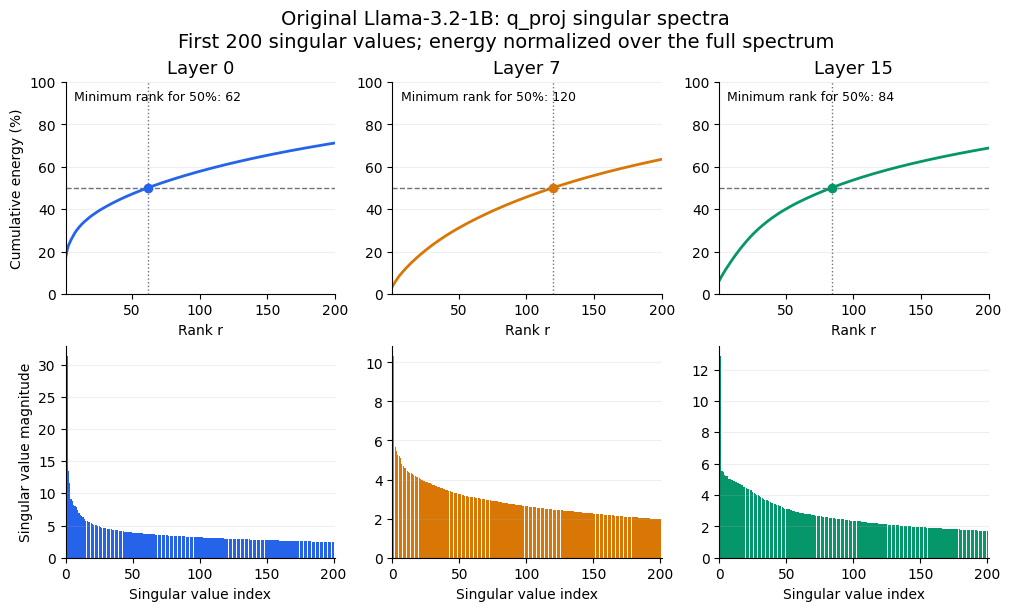

Results directory: /kaggle/working/Assignment1_Q4


In [13]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
COLORS = {0: '#2563EB', 7: '#D97706', 15: '#059669'}

def draw_energy(ax, layer):
    item = spectra[layer]
    n = min(PLOT_FIRST, len(item['s']))
    x = np.arange(1, n + 1)
    ax.plot(x, item['cumulative_pct'][:n], color=COLORS[layer], linewidth=2)
    ax.axhline(50, color='#6B7280', linestyle='--', linewidth=1)
    rank50 = item['rank50']
    if rank50 <= n:
        ax.axvline(rank50, color='#6B7280', linestyle=':', linewidth=1)
        ax.scatter(rank50, item['cumulative_pct'][rank50-1],
                   color=COLORS[layer], zorder=3)
    note = f'Minimum rank for 50%: {rank50}'
    if rank50 > n:
        note += ' (outside displayed range)'
    ax.text(0.03, 0.96, note, transform=ax.transAxes, va='top', fontsize=9)
    ax.set(title=f'Layer {layer}: cumulative energy', xlabel='Rank r',
           ylabel='Cumulative energy (%)', xlim=(1, n), ylim=(0, 100))
    ax.grid(axis='y', alpha=0.2)

def draw_magnitudes(ax, layer):
    s = spectra[layer]['s']
    n = min(PLOT_FIRST, len(s))
    ax.bar(np.arange(1, n + 1), s[:n], width=0.85, color=COLORS[layer])
    ax.set(title=f'Layer {layer}: singular value magnitudes',
           xlabel='Singular value index', ylabel='Singular value magnitude',
           xlim=(0, n + 1))
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.2)

# Six-panel figure: 2 rows × 3 columns.
fig, axes = plt.subplots(
    2, 3,
    figsize=(10, 6),
    layout='constrained'
)

for col, layer in enumerate([0, 7, 15]):
    # Top row: cumulative energy.
    draw_energy(axes[0, col], layer)
    axes[0, col].set_title(f'Layer {layer}', fontsize=13)

    # Bottom row: singular value magnitudes.
    draw_magnitudes(axes[1, col], layer)
    axes[1, col].set_title('')

    # Show the y-axis label only in the first column.
    if col > 0:
        axes[0, col].set_ylabel('')
        axes[1, col].set_ylabel('')

fig.suptitle(
    'Original Llama-3.2-1B: q_proj singular spectra\n'
    'First 200 singular values; energy normalized over the full spectrum',
    fontsize=14
)

for extension in ['png', 'pdf']:
    fig.savefig(
        OUT_DIR / f'Q4_all_layers.{extension}',
        dpi=300,
        bbox_inches='tight'
    )

plt.show()
plt.close(fig)

archive = shutil.make_archive(str(OUT_DIR.parent / 'Assignment1_Q4_results'),
                              'zip', root_dir=OUT_DIR)
print('Results directory:', OUT_DIR)
